In [65]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np

In [66]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [67]:
# 표준점수를 적용해서 전체 데이터와 [25,120] 을 scatter 그래프에 출력하시오
# 1. 데이터 전처리
# 2. 훈련데이터, 테스트테이터분리
# 3. 표준점수 작용
# 4. 데이터 학습
# 5. 데이터 예측
# 6. 정확도
# 7. 그래프 출력

In [68]:
# 1. 데이터 전처리
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
data = [[l,w] for l,w in zip(length,weight)]
label = [1]*35 + [0]*14
len(length)

49

In [69]:
# # 2. 훈련데이터, 테스트 데이터분리
# train_data,test_data, train_label, test_label =\
# train_test_split(train_scaled,label)

In [70]:
# # 2. 훈련데이터, 테스트 데이터분리
# 정규화가 안된 형태  - 훈련데이터, 테스트 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [71]:
# # 3.표준점수적용
# mean = np.mean(data, axis=0) # 열기준 평균 [길이평균,무게평균]
# std = np.std(data,axis=0) # 열 기준 표준편차
# train_scaled = (data-mean) / std # 젠체데이터에서 평균을 빼고 표준편차로 나눈 점수
# new_data = ([25,120]-mean) / std # 새 데이터도 같은 평균과 표준편차로 계산


In [72]:
# 3.표준점수적용

# 규제, 정규화 작업
ss = StandardScaler()
ss.fit(train_data) # 정규화 데이터로 훈련을 시켜야함
# ※ 평균·표준편차는 훈련데이터로만 구하고, test·새 데이터는 transform만
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)
new_scaled = ss.transform([[25,120]])
new_scaled

array([[-0.22833602, -1.04702922]])

In [73]:
# 4. 데이터 학습
clf = KNeighborsClassifier()
clf.fit(train_scaled, train_label)
# ※ 표준점수 값으로 학습해야 예측도 맞음 (train_data X)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [74]:
# 5. 데이터 예측
result = clf.predict(test_scaled)
# print('예측생선:','도미' if result == 1 else '빙어') # 도미


In [75]:
# 6. 정확도
score = clf.score(test_scaled, test_label)
print("정확도 :", score)

# kneighbors 알고리즘 사용시 사용
distances,indexes = clf.kneighbors(new_scaled)
indexes

정확도 : 1.0


array([[33,  5, 11,  4, 12]])

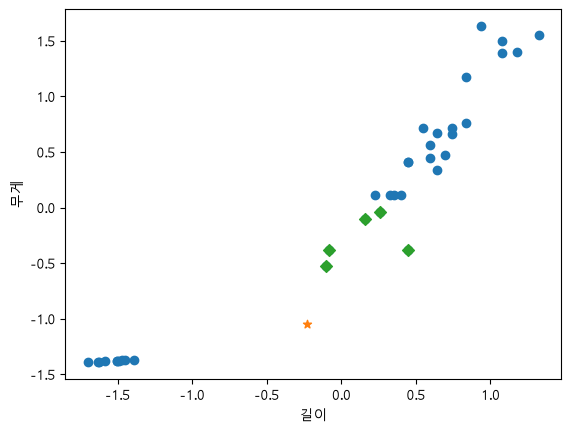

In [76]:
# 7. 그래프 출력
plt.scatter(train_scaled[:,0], train_scaled[:,1])   # 전체 데이터 (표준점수)
plt.scatter(new_scaled[:,0], new_scaled[:,1], marker='*')    # [25,120] (표준점수)
distances, indexes = clf.kneighbors(new_scaled)
plt.scatter(train_scaled[indexes,0], train_scaled[indexes,1], marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()